Rodrigo Baptista ist1114851
João Silva ist1113812

In [2]:
# Imports

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [3]:
# Dados

df = pd.read_csv("parkinsons.csv")
print(df.shape)
print("Valores em falta:", df.isna().sum().sum())
print("Pacientes:", df["subject#"].nunique())
df.head()

(5875, 21)
Valores em falta: 0
Pacientes: 42


,subject#,age,sex,test_time,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,...,Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE,total_UPDRS
0,1,72,0,5.6431,0.00662,0.000034,0.00401,0.00317,0.01204,0.02565,...,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006,34.398
1,1,72,0,12.6660,0.00300,0.000017,0.00132,0.00150,0.00395,0.02024,...,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810,34.894
2,1,72,0,19.6810,0.00481,0.000025,0.00205,0.00208,0.00616,0.01675,...,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014,35.389
3,1,72,0,25.6470,0.00528,0.000027,0.00191,0.00264,0.00573,0.02309,...,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277,35.810
4,1,72,0,33.6420,0.00335,0.000020,0.00093,0.00130,0.00278,0.01703,...,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361,36.375


## 3. Pacientes com maior vs menor gravidade

Cada paciente é ordenado pela média do seu total_UPDRS em todas as gravações. Comparam-se depois os 10 mais graves com os 10 menos graves nas features interpretáveis. A idade e o sexo são constantes por paciente, por isso são resumidos por paciente (caso contrário, pacientes com mais gravações pesariam mais). O test_time varia entre gravações, por isso é a média sobre as gravações. Para a feature categórica sex apresenta-se a moda, como pedido, e também a percentagem de sex=1, porque a moda sozinha não distingue os grupos.

In [6]:
patient_mean = df.groupby("subject#")["total_UPDRS"].mean().sort_values()
low_ids  = patient_mean.index[:10]     # 10 menores médias de total_UPDRS
high_ids = patient_mean.index[-10:]    # 10 maiores médias de total_UPDRS

def summarize(ids):
    sub = df[df["subject#"].isin(ids)]
    per_patient = sub.groupby("subject#").agg(age=("age", "first"), sex=("sex", "first"))
    return pd.Series({
        "total_UPDRS médio": sub["total_UPDRS"].mean(),
        "idade média (por paciente)": per_patient["age"].mean(),
        "sexo (moda)": sub["sex"].mode()[0],
        "% de pacientes com sex=1": per_patient["sex"].mean() * 100,
        "test_time médio (dias)": sub["test_time"].mean(),
        "gravações por paciente": len(sub) / len(ids),
    })

summary = pd.DataFrame({"10 mais graves": summarize(high_ids), "10 menos graves": summarize(low_ids)})
summary.round(2)

,10 mais graves,10 menos graves
total_UPDRS médio,43.07,15.76
idade média (por paciente),66.90,58.10
sexo (moda),0.00,0.00
% de pacientes com sex=1,20.00,40.00
test_time médio (dias),89.55,91.62
gravações por paciente,146.70,132.50


A diferença mais clara entre os dois grupos é a idade: os 10 pacientes mais graves são em média cerca de 9 anos mais velhos do que os 10 menos graves (≈ 66.9 vs ≈ 58.1 anos). Quanto ao sexo, a moda é a mesma (sex=0) nos dois grupos, logo não os distingue, mas a percentagem de pacientes com sex=1 é maior no grupo menos grave (40% vs 20%), o que sugere que o grupo mais grave tem relativamente mais pacientes com sex=0. O test_time é praticamente igual nos dois grupos (≈ 89.6 vs ≈ 91.6 dias), o que era esperado, já que todos os pacientes foram seguidos durante a mesma janela de seis meses e, por isso, o tempo desde o recrutamento não distingue a gravidade. Estas conclusões são apenas estatísticas descritivas sobre 10 + 10 pacientes: mostram associação e não causalidade, não foi feito nenhum teste estatístico, e com tão poucos pacientes as diferenças de sexo devem ser vistas como indicativas.

## Preparação para as perguntas 4 a 7

Os inputs são todas as colunas exceto total_UPDRS, incluindo subject#, porque o enunciado a lista como input. O StandardScaler é ajustado apenas no conjunto de treino de cada split e depois aplicado ao treino e ao teste, para que as estatísticas do teste não passem para o treino (data leakage).

In [7]:
X = df.drop(columns="total_UPDRS")
y = df["total_UPDRS"]
groups = df["subject#"]

def build_models():
    return {
        "Linear Regression": LinearRegression(),
        "MLP identity": MLPRegressor(hidden_layer_sizes=(10, 10), activation="identity",
                                     max_iter=500, random_state=0),
        "MLP ReLU": MLPRegressor(hidden_layer_sizes=(10, 10), activation="relu",
                                 max_iter=500, random_state=0),
    }

def fit_and_evaluate(X_train, X_test, y_train, y_test):
    # o scaler é ajustado só nos dados de treino
    scaler = StandardScaler().fit(X_train)
    X_train_sc = scaler.transform(X_train)
    X_test_sc = scaler.transform(X_test)

    models, rows = build_models(), []
    for name, model in models.items():
        model.fit(X_train_sc, y_train)
        rows.append({
            "model": name,
            "train MAE": mean_absolute_error(y_train, model.predict(X_train_sc)),
            "test MAE":  mean_absolute_error(y_test,  model.predict(X_test_sc)),
        })
    return models, pd.DataFrame(rows).set_index("model"), X_test_sc

def plot_mae(results, title):
    d = results.reset_index().melt(id_vars="model", var_name="set", value_name="MAE")
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=d, x="model", y="MAE", hue="set")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("MAE (pontos de total_UPDRS)")
    plt.tight_layout()
    plt.show()

## 4. Split aleatório 70/30

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

models_rand, results_rand, Xte_rand = fit_and_evaluate(X_train, X_test, y_train, y_test)
results_rand.round(3)

,train MAE,test MAE
model,,
Linear Regression,7.654,7.405
MLP identity,7.665,7.399
MLP ReLU,2.702,2.867


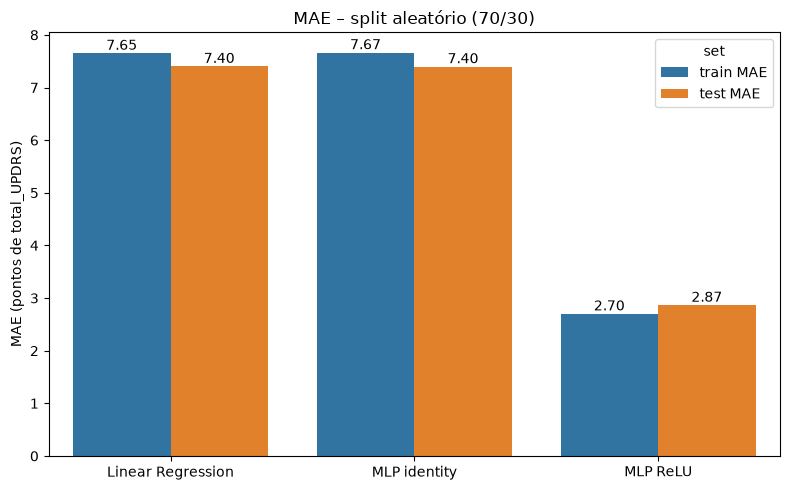

In [ ]:
plot_mae(results_rand, "MAE - split aleatório (70/30)")

Com o split aleatório, os dois modelos lineares (Regressão Linear e MLP com ativação identidade) têm um MAE quase igual (≈ 7.4 no teste), enquanto o MLP com ReLU é muito melhor (≈ 2.9 no teste), com erros de treino e teste próximos. À primeira vista o MLP ReLU parece claramente o melhor modelo, mas a pergunta 5 mostra porque isso engana.

## 5. Split por grupos (cada paciente é um grupo)

In [10]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

Xg_train, Xg_test = X.iloc[train_idx], X.iloc[test_idx]
yg_train, yg_test = y.iloc[train_idx], y.iloc[test_idx]

# verificação: nenhum paciente pode estar nos dois conjuntos
shared = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print("Pacientes no treino:", groups.iloc[train_idx].nunique(),
      "| no teste:", groups.iloc[test_idx].nunique(),
      "| partilhados:", shared)

models_grp, results_grp, Xte_grp = fit_and_evaluate(Xg_train, Xg_test, yg_train, yg_test)
results_grp.round(3)

Pacientes no treino: 29 | no teste: 13 | partilhados: set()


,train MAE,test MAE
model,,
Linear Regression,6.860,11.014
MLP identity,6.896,10.955
MLP ReLU,1.215,17.619


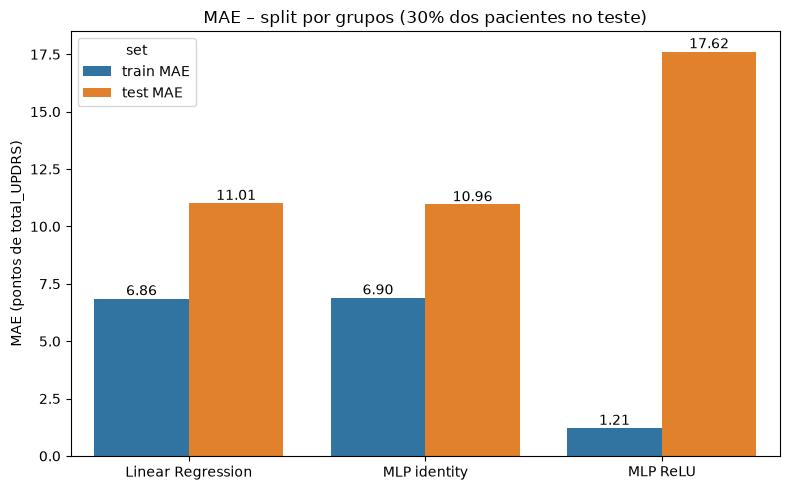

In [ ]:
plot_mae(results_grp, "MAE - split por grupos (30% dos pacientes no teste)")

## 6. Comparação entre as perguntas 4 e 5

In [12]:
comparison = pd.concat({"split aleatório": results_rand, "split por grupos": results_grp}, axis=1)
comparison.round(2)

split aleatório          split por grupos         
                        train MAE test MAE        train MAE test MAE
model                                                               
Linear Regression            7.65     7.40             6.86    11.01
MLP identity                 7.67     7.40             6.90    10.96
MLP ReLU                     2.70     2.87             1.21    17.62

O MLP ReLU é o modelo que mais muda entre os dois splits: o MAE de teste passa de ≈ 2.9, o melhor de todos os modelos, para ≈ 17.6, o pior, enquanto o MAE de treino é de apenas ≈ 1.2, o que indica overfitting severo. A explicação está na forma como o split aleatório é feito. Como gravações do mesmo paciente aparecem tanto no treino como no teste, e subject#, age e sex são constantes para cada paciente, estas três features funcionam em conjunto como um identificador do paciente. Um modelo não linear flexível consegue memorizar a associação "paciente → nível de gravidade" a partir do treino e reutilizá-la nas gravações de teste do mesmo paciente, pelo que o erro baixo reflete a memorização dos pacientes e não a aprendizagem da doença. Com o split por grupos, os pacientes de teste nunca foram vistos no treino, o atalho desaparece e o erro dispara. Os modelos lineares degradam menos (≈ 7.4 → ≈ 11.0), porque têm pouca capacidade de memorizar, mas também pioram, uma vez que têm de prever para pacientes novos. O MLP com ativação identidade comporta-se como a Regressão Linear, com um MAE quase igual nos dois splits, pois camadas lineares empilhadas continuam a dar uma função linear, sem qualquer ganho de expressividade. Em conclusão, um MAE mais baixo só significa um modelo melhor se a avaliação corresponder ao uso pretendido. Aqui o objetivo realista é prever para pacientes novos, por isso o split por grupos é a estimativa honesta, e é sob esse split que o ranking dos modelos se inverte. O MLP ReLU não deve, portanto, ser apresentado como o melhor modelo com base no split aleatório.

## 7. Permutation feature importance

Reutilizam-se os modelos ajustados nas perguntas 4 e 5 e os conjuntos de teste standardizados devolvidos por fit_and_evaluate(os modelos foram treinados com dados standardizados, por isso o teste tem de estar no mesmo espaço; nada foi modificado). Com scoring='neg_mean_absolute_error', a importância de uma feature é o aumento do MAE no teste quando os seus valores são baralhados.

In [13]:
def importance_df(models, X_test_sc, y_test):
    out = {}
    for name in ["Linear Regression", "MLP ReLU"]:
        r = permutation_importance(models[name], X_test_sc, y_test,
                                   scoring="neg_mean_absolute_error",
                                   n_repeats=5, random_state=0)
        out[name] = pd.Series(r.importances_mean, index=X.columns)
    return pd.DataFrame(out)

imp_rand = importance_df(models_rand, Xte_rand, y_test)
imp_grp  = importance_df(models_grp,  Xte_grp,  yg_test)

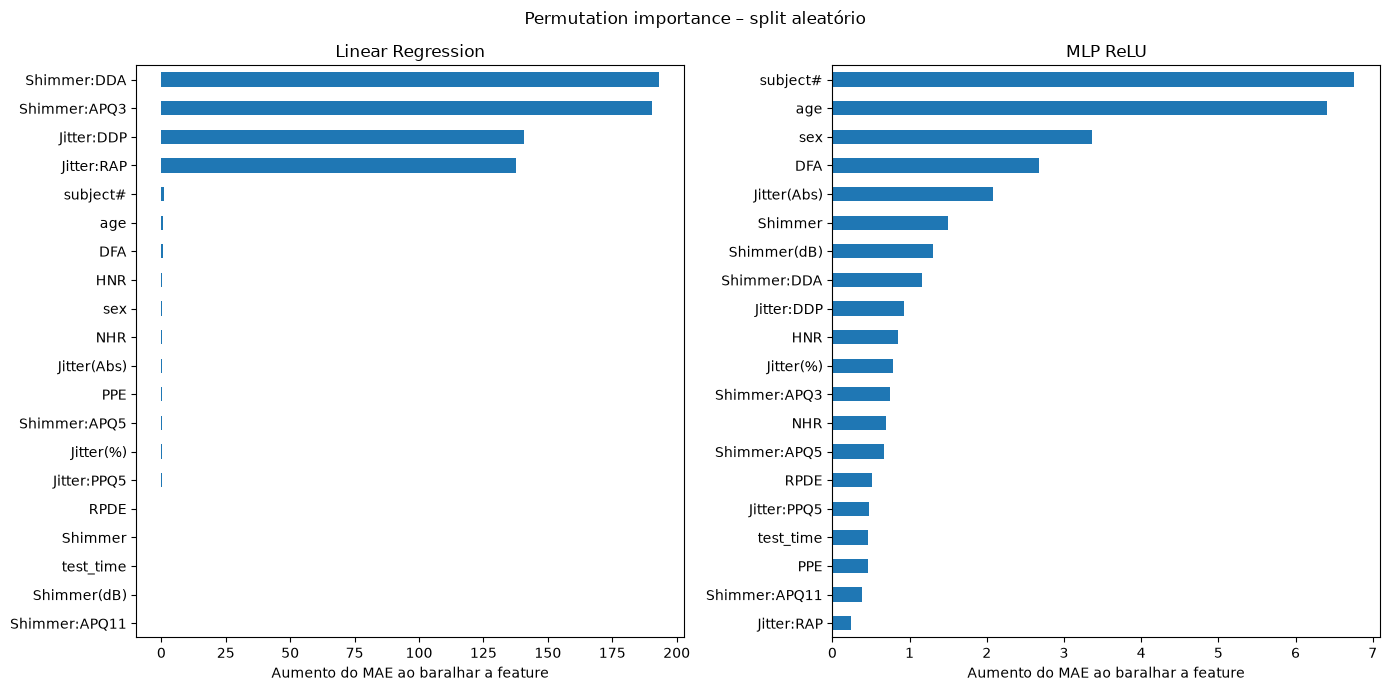

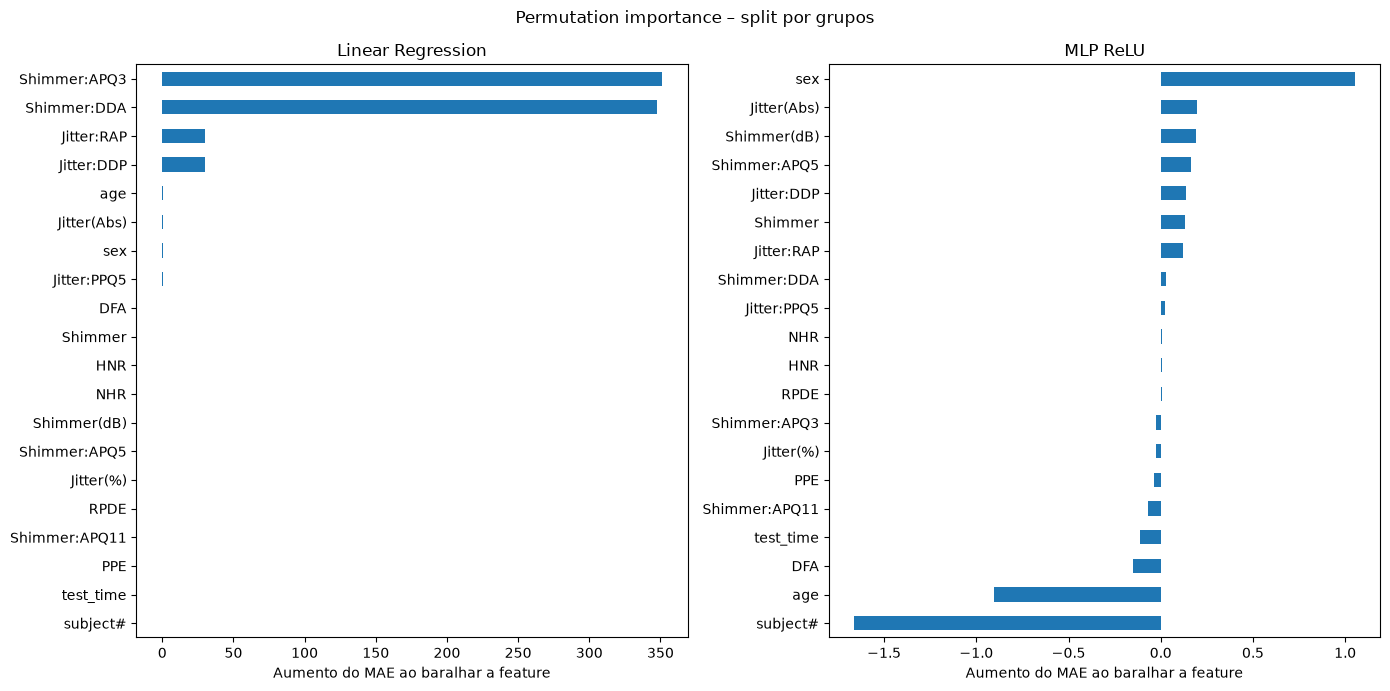

In [ ]:
def plot_importance(imp, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, name in zip(axes, imp.columns):
        imp[name].sort_values().plot.barh(ax=ax)
        ax.set_title(name)
        ax.set_xlabel("Aumento do MAE ao baralhar a feature")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_importance(imp_rand, "Permutation importance - split aleatório")
plot_importance(imp_grp,  "Permutation importance - split por grupos")

In [ ]:
print("Split aleatório - top 6 pelo MLP ReLU"); display(imp_rand.sort_values("MLP ReLU", ascending=False).head(6).round(2))
print("Split aleatório - top 6 pela Regressão Linear"); display(imp_rand.sort_values("Linear Regression", ascending=False).head(6).round(2))
print("Split por grupos - top 6 pelo MLP ReLU"); display(imp_grp.sort_values("MLP ReLU", ascending=False).head(6).round(2))
print("Split por grupos - top 6 pela Regressão Linear"); display(imp_grp.sort_values("Linear Regression", ascending=False).head(6).round(2))

Split aleatório – top 6 pelo MLP ReLU


,Linear Regression,MLP ReLU
subject#,0.88,6.76
age,0.66,6.40
sex,0.28,3.37
DFA,0.57,2.68
Jitter(Abs),0.21,2.08
Shimmer,0.00,1.50


Split aleatório – top 6 pela Regressão Linear


,Linear Regression,MLP ReLU
Shimmer:DDA,193.21,1.16
Shimmer:APQ3,190.44,0.74
Jitter:DDP,140.85,0.92
Jitter:RAP,137.66,0.24
subject#,0.88,6.76
age,0.66,6.40


Split por grupos – top 6 pelo MLP ReLU


,Linear Regression,MLP ReLU
sex,0.20,1.05
Jitter(Abs),0.24,0.20
Shimmer(dB),0.01,0.19
Shimmer:APQ5,-0.00,0.16
Jitter:DDP,30.12,0.13
Shimmer,0.04,0.13


Split por grupos – top 6 pela Regressão Linear


,Linear Regression,MLP ReLU
Shimmer:APQ3,351.39,-0.02
Shimmer:DDA,347.54,0.03
Jitter:RAP,30.18,0.12
Jitter:DDP,30.12,0.13
age,0.45,-0.90
Jitter(Abs),0.24,0.20


## 7a. Em que features se apoia o MLP ReLU e como muda o ranking?

No split aleatório, o MLP ReLU apoia-se sobretudo em subject# (≈ 6.8 de aumento do MAE), age (≈ 6.4) e sex (≈ 3.4), seguidas de medidas de voz como DFA (≈ 2.7) e Jitter(Abs) (≈ 2.1). As três primeiras são constantes por paciente, ou seja, identificam o paciente, o que confirma a explicação da pergunta 6: a rede usa-as para reconhecer o paciente e recuperar a gravidade que memorizou, e é por isso que se sai tão bem neste split. No split por grupos, as importâncias colapsam, com apenas sex (≈ 1.0) a continuar visível e todas as restantes abaixo de 0.2, e subject# e age deixam de estar no topo, porque os pacientes de teste são novos e a sua identidade não traz informação. Isto não significa que o modelo passe a usar as features certas: o MAE de teste é ≈ 17.6, pelo que se trata simplesmente de um modelo mau, cujas pequenas dependências restantes não são fiáveis. Na Regressão Linear, as maiores importâncias (Shimmer:APQ3/Shimmer:DDA e Jitter:RAP/Jitter:DDP, com valores de dezenas ou centenas) são um artefacto de colinearidade, pois por definição Shimmer:DDA = 3 × Shimmer:APQ3 e Jitter:DDP = 3 × Jitter:RAP. O modelo atribui coeficientes muito grandes e de sinal oposto a variáveis quase idênticas, que se cancelam entre si, e ao baralhar só uma delas o cancelamento quebra e o erro explode, o que não significa que estas medidas de voz sejam clinicamente importantes.

## 7b O que a permutation importance diz e não diz

A permutation importance diz-nos de que features este modelo ajustado depende para prever neste conjunto de teste, medido pela perda de precisão quando se destrói a relação entre a feature e o target, e pode também expor atalhos, como a dependência de identificadores de pacientes. No entanto, não nos diz nada de fiável sobre a doença. Em primeiro lugar, não dá causalidade nem mecanismo: uma feature importante para o modelo não é necessariamente causa ou biomarcador de Parkinson, e a age, por exemplo, conta porque se correlaciona com a gravidade nesta amostra. Em segundo lugar, é pouco fiável com features correlacionadas, uma vez que a importância pode ser repartida ou exagerada entre variáveis correlacionadas, como nas famílias Shimmer e Jitter. Em terceiro lugar, não é estável: o ranking mudou por completo entre o split aleatório e o split por grupos, logo depende do modelo, do split e do conjunto de teste, e não generaliza para pacientes novos por si só. Por fim, explica o modelo e não a realidade, pois se o modelo está errado (MAE de teste ≈ 17.6 no split por grupos), a explicação descreve um modelo falho e não a doença.